## 0. 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from imblearn.pipeline import Pipeline      # SMOTE를 넣으려면 imblearn의 Pipeline 사용
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42

## 1. 데이터 통계치 확인

In [2]:
import pandas as pd

df = pd.read_csv('./bank-full.csv', sep=';')
print('\n데이터 행 열 개수')
print(df.shape)
print('\n데이터 숫자 통계치')
print(df.describe(include='all'))
print('\n칼럼명 확인')
print(df.columns.tolist())
print('\n칼럼별 결측치 확인')
print(df.isnull().sum())
print('\n중복 데이터 확인')
print(df.duplicated().sum())


데이터 행 열 개수
(45211, 17)

데이터 숫자 통계치
                 age          job  marital  education default        balance  \
count   45211.000000        45211    45211      45211   45211   45211.000000   
unique           NaN           12        3          4       2            NaN   
top              NaN  blue-collar  married  secondary      no            NaN   
freq             NaN         9732    27214      23202   44396            NaN   
mean       40.936210          NaN      NaN        NaN     NaN    1362.272058   
std        10.618762          NaN      NaN        NaN     NaN    3044.765829   
min        18.000000          NaN      NaN        NaN     NaN   -8019.000000   
25%        33.000000          NaN      NaN        NaN     NaN      72.000000   
50%        39.000000          NaN      NaN        NaN     NaN     448.000000   
75%        48.000000          NaN      NaN        NaN     NaN    1428.000000   
max        95.000000          NaN      NaN        NaN     NaN  102127.000000   

   

## 2. unknown 현황 확인(건수, 비율)

In [3]:
# unknown 현황 다시 확인
unknown_cols = ['job', 'education', 'contact', 'poutcome']
for col in unknown_cols:
    print(f"{col}: {(df[col] == 'unknown').sum()}건 ({(df[col] == 'unknown').mean()*100:.2f}%)")

# job: 행 삭제 / education: 직업별 최빈값 대체 (3·4번에서 처리)
# contact, poutcome: 별도 대체 없이 'unknown'을 하나의 범주로 유지
# → 이후 원-핫 인코딩 시 contact_unknown, poutcome_unknown으로 자동 생성됨

job: 288건 (0.64%)
education: 1857건 (4.11%)
contact: 13020건 (28.80%)
poutcome: 36959건 (81.75%)


## 3. 데이터 중복치 탐지 및 X, y 분리

- duration 칼럼이 데이터 누수를 발생시키기 때문에 모델링 과정에서 제외함.
- duration 칼럼 제외 후 중복 건수가 16건(전체의 약 0.035%) 발생함.
- 비율은 매우 작지만, 동일한 행이 Train과 Test에 나뉘어 들어가는 누수를 막기 위해 **분할 전에 제거**함.
- 이 셀에서 X, y를 만들기 때문에 반드시 4번(분할)보다 먼저 실행해야 함.
- 참고: 완전히 같은 행은 아니지만 같은 고객이 여러 캠페인에 걸쳐 반복 등장하는 경우도 확인됨. 현재 단계에서는 duration 제거로 생긴 중복만 처리하고, 반복 고객 문제는 추후 모델 평가에서 문제가 될 경우 고객 단위 분할 등으로 고려함.

In [4]:
df = pd.read_csv('bank-full.csv', sep=';')

df = df.drop(columns=['duration'])
print('중복 건수:', df.duplicated().sum())   # 16

df = df.drop_duplicates().reset_index(drop=True)
print('제거 후 shape:', df.shape)            # (45195, 16)

X = df.drop(columns=['y'])
y = (df['y'] == 'yes').astype(int)

중복 건수: 16
제거 후 shape: (45195, 16)


## 4. 데이터 분할 및 결측치 전처리
#### job은 행 삭제
#### education은 직업별 최빈값 대체 (Train 기준 계산 → Val·Test에 동일 적용)

In [5]:
# 1) Train / Val / Test = 60 : 20 : 20 분할
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

# 2) 각 데이터셋에서 job unknown 행 삭제 (X와 y를 같은 행으로 삭제)
def drop_job_unknown(X_part, y_part):
    keep = X_part['job'] != 'unknown'
    return X_part[keep].copy(), y_part[keep].copy()

X_train, y_train = drop_job_unknown(X_train, y_train)
X_val,   y_val   = drop_job_unknown(X_val,   y_val)
X_test,  y_test  = drop_job_unknown(X_test,  y_test)

# 3) Train에서만 직업별 education 최빈값 계산 (job unknown 삭제 후)
edu_map = (X_train[X_train['education'] != 'unknown']
           .groupby('job')['education']
           .agg(lambda s: s.mode()[0]))

# 4) Train / Val / Test에 같은 최빈값으로 대체
for data in [X_train, X_val, X_test]:
    mask = data['education'] == 'unknown'
    data.loc[mask, 'education'] = data.loc[mask, 'job'].map(edu_map)

# 5) 확인
for name, data, target in [('Train', X_train, y_train), ('Val', X_val, y_val), ('Test', X_test, y_test)]:
    print(f"{name}: {data.shape}, 가입 비율 {target.mean()*100:.2f}%, "
          f"NaN {data.isna().sum().sum()}건, "
          f"job unknown {(data['job'] == 'unknown').sum()}건, "
          f"education unknown {(data['education'] == 'unknown').sum()}건")

Train: (26931, 15), 가입 비율 11.70%, NaN 0건, job unknown 0건, education unknown 0건
Val: (8986, 15), 가입 비율 11.70%, NaN 0건, job unknown 0건, education unknown 0건


Test: (8990, 15), 가입 비율 11.71%, NaN 0건, job unknown 0건, education unknown 0건


In [6]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

check = pd.DataFrame({
    name: (data[cat_cols] == 'unknown').sum()
    for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]
})
print(check)

           Train   Val  Test
job            0     0     0
marital        0     0     0
education      0     0     0
default        0     0     0
housing        0     0     0
loan           0     0     0
contact     7797  2491  2619
month          0     0     0
poutcome   21996  7357  7335


In [7]:
for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]:
    print(f"{name} - NaN: {data.isna().sum().sum()}건, "
          f"job unknown: {(data['job'] == 'unknown').sum()}건, "
          f"education unknown: {(data['education'] == 'unknown').sum()}건")

Train - NaN: 0건, job unknown: 0건, education unknown: 0건
Val - NaN: 0건, job unknown: 0건, education unknown: 0건
Test - NaN: 0건, job unknown: 0건, education unknown: 0건


#### education 대체 근거: 직업과 학력의 연관성
- 직업과 학력은 둘 다 범주형 변수이므로, 피어슨 상관계수 대신 **교차표 · 카이제곱 검정 · Cramér's V**로 관계를 확인함.
  - 카이제곱 검정: '두 변수가 서로 관련이 없다'는 가정을 검정 (p < 0.05이면 관련 있음)
  - Cramér's V: 관련의 강도를 0~1로 표현 (0.1 이상 약함, 0.3 이상 중간, 0.5 이상 강함)
- 누수 방지를 위해 **Train 데이터 중 job과 education이 모두 알려진 행**만 사용함.
  - X_train의 education은 이미 대체된 상태이므로, 대체 전 원본인 `X.loc[X_train.index]`에서 가져옴.

In [8]:
base = X.loc[X_train.index]      # 대체 전 Train 원본 (job unknown은 이미 제외된 행)
known = base[(base['job'] != 'unknown') & (base['education'] != 'unknown')].copy()
print('분석 대상:', len(known), '건')

edu_by_job = (pd.crosstab(known['job'], known['education'], normalize='index') * 100).round(1)
edu_by_job

분석 대상: 25893 건


education,primary,secondary,tertiary
job,,,
admin.,4.1,84.3,11.6
blue-collar,40.7,57.7,1.6
entrepreneur,12.3,36.9,50.8
housemaid,52.4,33.7,13.9
management,3.2,11.7,85.1
retired,36.7,45.9,17.5
self-employed,7.7,37.7,54.6
services,8.5,86.3,5.1
student,5.8,63.8,30.5


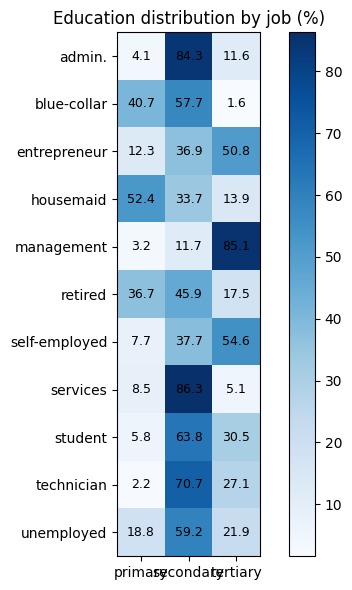

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(edu_by_job.values, cmap='Blues')
ax.set_xticks(range(edu_by_job.shape[1])); ax.set_xticklabels(edu_by_job.columns)
ax.set_yticks(range(edu_by_job.shape[0])); ax.set_yticklabels(edu_by_job.index)
for i in range(edu_by_job.shape[0]):
    for j in range(edu_by_job.shape[1]):
        ax.text(j, i, edu_by_job.values[i, j], ha='center', va='center', fontsize=9)
ax.set_title('Education distribution by job (%)')
plt.colorbar(im)
plt.tight_layout()
plt.show()

In [10]:
from scipy.stats import chi2_contingency

def cramers_v(data, col, target='education'):
    table = pd.crosstab(data[col], data[target])
    chi2, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return chi2, p, v

chi2, p, v = cramers_v(known, 'job')
print(f"직업 vs 학력 → 카이제곱 = {chi2:,.1f}, p-value = {p:.3g}, Cramér's V = {v:.3f}")

직업 vs 학력 → 카이제곱 = 16,040.2, p-value = 0, Cramér's V = 0.557


In [11]:
# 다른 변수와 비교: 학력을 추정하기에 직업이 가장 적합한가?
known['age_group'] = pd.cut(known['age'], bins=[0, 29, 39, 49, 59, 100])

compare = pd.DataFrame({
    col: {"Cramér's V": round(cramers_v(known, col)[2], 3)}
    for col in ['job', 'age_group', 'marital', 'housing', 'contact', 'loan', 'default']
}).T.sort_values("Cramér's V", ascending=False)
compare

,Cramér's V
job,0.557
age_group,0.153
marital,0.127
contact,0.124
housing,0.110
loan,0.061
default,0.011


#### 직업-학력 연관성 판단
- 직업별 학력 분포가 뚜렷하게 구분됨: management는 85.1%가 tertiary, services(86.3%)와 admin.(84.3%)은 대부분 secondary, housemaid는 52.4%가 primary.
- 카이제곱 검정 결과 p < 0.001로 직업과 학력 사이에 통계적으로 유의한 관계가 있으며, Cramér's V = 0.557로 **강한 연관성**을 보임.
- 다른 변수와 비교하면 연령대(0.153), 결혼 상태(0.127), 연락 방식(0.124) 등보다 **3배 이상** 높아, 학력을 추정하기에 직업이 가장 적합한 변수임.
- 연령대를 함께 사용해도 대체 정확도가 거의 오르지 않았던 이유도, 연령대와 학력의 연관성이 직업에 비해 약하기 때문으로 설명됨.
- **결론:** education의 unknown은 Train 기준 직업별 최빈값으로 대체함.

## 5. 데이터 이상치 탐지

In [12]:
import matplotlib.pyplot as plt
num_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

#### IQR로 이상치 후보 탐지
- pdays와 previous는 IQR이 0. (값이 대부분 -1과 0이어서, 이전 연락 기록이 있는 고객 전체가 이상치로 잡힌 것으로 판단됨.) -> 이 두 변수는 IQR로 판단하면 안 된다.

In [13]:
rows = []
for col in num_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = (X_train[col] < lower) | (X_train[col] > upper)

    rows.append({
        '컬럼': col, '하한': lower, '상한': upper,
        '이상치 건수': out.sum(),
        '비율(%)': round(out.mean() * 100, 2),
        '이상치 가입률(%)': round(y_train[out].mean() * 100, 1) if out.any() else None,
        '정상 가입률(%)': round(y_train[~out].mean() * 100, 1)
    })

iqr_table = pd.DataFrame(rows).set_index('컬럼')
display(iqr_table)

,하한,상한,이상치 건수,비율(%),이상치 가입률(%),정상 가입률(%)
컬럼,,,,,,
age,10.5,70.5,287,1.07,44.3,11.3
balance,-1944.5,3443.5,2829,10.50,16.0,11.2
day,-11.5,40.5,0,0.00,NaN,11.7
campaign,-2.0,6.0,1821,6.76,5.1,12.2
pdays,-1.0,-1.0,4939,18.34,22.6,9.3
previous,0.0,0.0,4939,18.34,22.6,9.3


#### 시각화로 분포 확인
시각화 목적:
- 극단값이 몇 개만 동떨어져 있는지, 아니면 꼬리가 길게 이어지는지
- 분포가 한쪽으로 얼마나 치우쳐 있는지
- 이상치가 가입 여부(y)와 관련이 있는지

#### 박스플롯 + 히스토그램

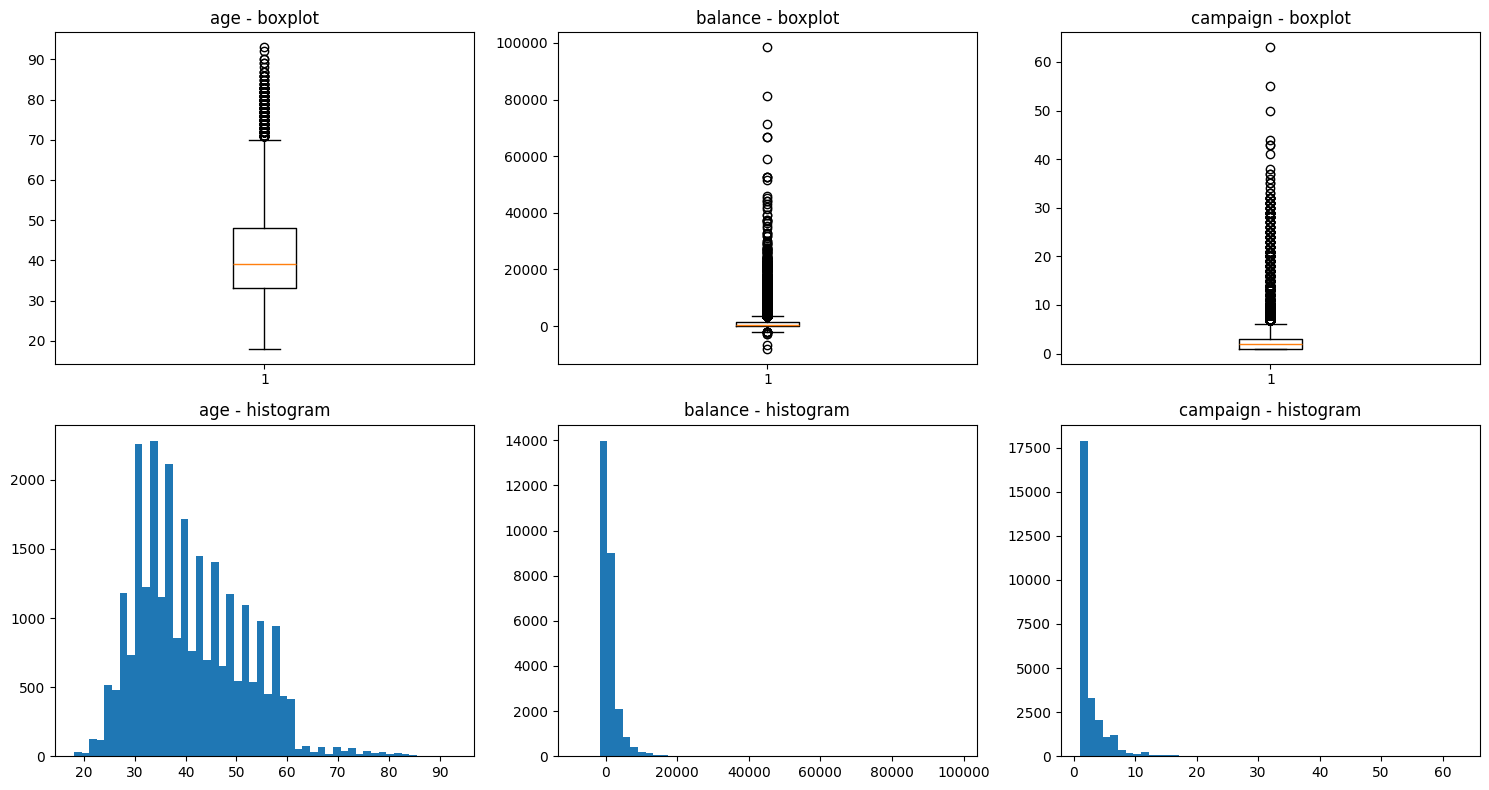

In [14]:
check_cols = ['age', 'balance', 'campaign']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(check_cols):
    axes[0, i].boxplot(X_train[col])
    axes[0, i].set_title(f'{col} - boxplot')

    axes[1, i].hist(X_train[col], bins=50)
    axes[1, i].set_title(f'{col} - histogram')
plt.tight_layout()
plt.show()

#### 박스플롯 + 히스토그램 해석
- age (나이): 
age는 상자가 약 33~48세, 중앙값이 약 39세로 고객 대부분이 25~60세에 분포하며, 60세를 넘으면 고객 수가 급격히 줄어든다. 박스플롯에서 70세를 넘는 값이 이상치로 표시되었으나, 71세부터 93세까지 띄엄띄엄 떨어지지 않고 연속적으로 이어져 있어 입력 오류가 아닌 실제 고령 고객층으로 판단하였다. 따라서 age의 이상치는 별도로 처리하지 않고 유지한다.

- balance (잔고): 
balance는 대부분 고객의 잔고가 0~5,000 근처에 몰려 있고, 소수의 고액 잔고 고객으로 인해 오른쪽으로 꼬리가 매우 긴 분포를 보인다. 이상치는 약 45,000까지 촘촘히 이어지다가 6만~10만 사이에 드문드문 존재하며, 0 아래로도 약 -8,000까지 음수 잔고가 나타난다. 고액 잔고와 음수 잔고(마이너스 통장 등)는 모두 현실적으로 가능한 값이므로 유지하되, 분포의 치우침이 심해 Logistic Regression 적용 시 로그 변환을 검토한다.

- campaign (이번 캠페인 연락 횟수): 
campaign은 고객 대부분이 1~3회 연락을 받았으며, 연락 횟수가 늘수록 고객 수가 빠르게 줄어드는 오른쪽으로 꼬리가 긴 분포를 보인다. 7회부터 약 40회까지 이상치가 연속적으로 이어지고, 50, 55, 63회와 같이 일부 값만 동떨어져 있다. 이는 같은 고객에게 여러 번 연락한 실제 기록으로 볼 수 있고 0회 이하와 같은 규칙 위반도 없으므로 유지하되, Logistic Regression 적용 시 상위 값을 잘라내는 클리핑을 검토한다.

#### 가입 여부별 박스 플롯

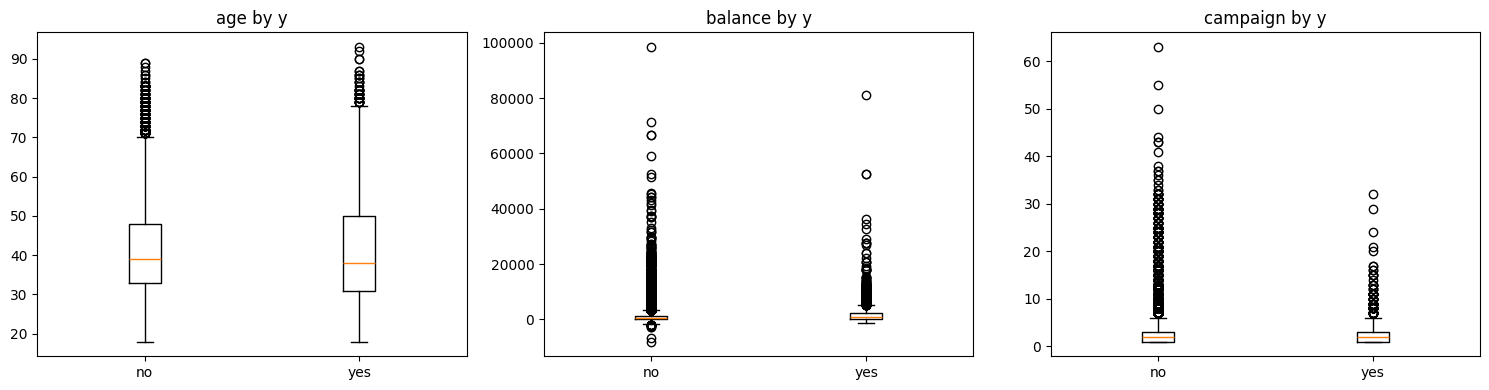

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, check_cols):
    ax.boxplot([X_train.loc[y_train == 0, col], X_train.loc[y_train == 1, col]],
               tick_labels=['no', 'yes'])
    ax.set_title(f'{col} by y')
plt.tight_layout()
plt.show()

#### 가입 여부별 박스플롯 해석
- age (나이): 
가입 고객과 미가입 고객의 중앙값은 각각 약 38세, 39세로 비슷하지만, 가입 고객의 상자(약 31~50세)가 미가입 고객(약 33~48세)보다 위아래로 더 넓게 퍼져 있다. 특히 위쪽 수염이 미가입 고객은 70세에서 끝나는 반면 가입 고객은 약 78세까지 이어져, 가입 고객 중 고령층의 비중이 상대적으로 크다는 것을 알 수 있다. 즉 나이의 평균적인 수준보다는 젊은 층과 고령층처럼 양 끝 연령대에서 가입 경향이 나타나며, 고령 고객의 이상치는 가입 여부를 구분하는 데 유용한 정보로 판단된다.

- balance (잔고): 
두 그룹 모두 상자가 0 근처에 납작하게 눌려 있으나, 가입 고객의 상자가 미가입 고객보다 약간 위쪽으로 넓게 형성되어 있어 가입 고객의 잔고가 전반적으로 조금 더 높은 경향을 보인다. 음수 잔고는 미가입 고객에서 약 -8,000까지 나타나는 반면 가입 고객에서는 0에 가까운 범위에 그친다. 다만 고액 잔고 이상치는 두 그룹 모두에 존재해 특정 그룹에만 나타나는 값이 아니며, 극단값으로 인해 축 범위가 넓어져 차이를 자세히 보기 어려우므로 로그 변환 후 다시 확인할 필요가 있다.

- campaign (이번 캠페인 연락 횟수): 
두 그룹 모두 상자가 1~3회, 중앙값이 약 2회로 일반적인 연락 횟수는 비슷하다. 그러나 미가입 고객은 이상치가 63회까지 이어지는 반면, 가입 고객은 최대 약 32회에 그치고 20회 이상은 드물게 나타난다. 이는 많이 연락한다고 해서 가입으로 이어지지 않으며, 연락 횟수가 매우 많은 고객은 대부분 가입하지 않았음을 보여준다.

#### 꼬리부분 확인(백분위수)


In [16]:
print(X_train[check_cols].describe(percentiles=[0.01, 0.99]).round(1))

           age  balance  campaign
count  26931.0  26931.0   26931.0
mean      40.8   1352.9       2.8
std       10.6   2996.9       3.1
min       18.0  -8019.0       1.0
1%        23.0   -624.7       1.0
99%       71.0  12956.0      16.0
max       93.0  98417.0      63.0


#### 확인 및 판단 내용
- age: 99% 지점이 71세이고 최대는 93세입니다. 70세 이상 고객이 꾸준히 이어져 있어, 동떨어진 오류값이 아니라 고령층 고객군으로 보입니다.
- balance: 오른쪽 꼬리가 매우 깁니다. 99% 지점이 약 13,000인데 최대값은 약 98,000입니다. 
- campaign: 99% 지점이 16회인데 최대 63회까지 있습니다. 40회 이상은 몇 건씩만 드문드문 있습니다.

#### 도메인으로 규칙 판단
- 오류값: 현실에서 불가능한 값(-5세, 32일등) -> 삭제 및 수정
- 극단값: 드물지만 실제로 있을 수 있는 값(93세 등) -> 유지

#### 오류값 규칙 점검

In [17]:
rules = {
    'age':      (X_train['age'] < 18) | (X_train['age'] > 100),   # 성인 고객, 100세 이하
    'day':      (X_train['day'] < 1) | (X_train['day'] > 31),     # 날짜 범위
    'campaign': X_train['campaign'] < 1,                          # 현재 캠페인에서 최소 1회는 연락
    'previous': X_train['previous'] < 0,                          # 횟수는 음수 불가
    'pdays':    (X_train['pdays'] < -1) | (X_train['pdays'] == 0) # -1(연락 없음) 또는 양수만 가능
}

for col, violated in rules.items():
    print(f"{col}: 규칙 위반 {violated.sum()}건")

age: 규칙 위반 0건
day: 규칙 위반 0건
campaign: 규칙 위반 0건
previous: 규칙 위반 0건
pdays: 규칙 위반 0건


#### 극단값 세부 확인

In [18]:
print('음수 잔액 비율:', round((X_train['balance'] < 0).mean() * 100, 2), '%')
print('71세 이상(IQR 상한 70.5세 초과):', (X_train['age'] > 70.5).sum(), '건')
print('잔고 50,000 초과:', (X_train['balance'] > 50000).sum(), '건')
print('campaign 상위 값:', X_train['campaign'].value_counts().sort_index().tail(8).to_dict())

음수 잔액 비율: 8.31 %
71세 이상(IQR 상한 70.5세 초과): 287 건
잔고 50,000 초과: 10 건
campaign 상위 값: {37: 2, 38: 1, 41: 1, 43: 2, 44: 1, 50: 1, 55: 1, 63: 1}


#### previous 오류값 처리
- previous의 최대값 275는 다음으로 큰 값(58)과 약 5배 차이가 나며 혼자 동떨어져 있음.
- 다른 극단값처럼 연속적으로 이어지지 않으므로 **입력 오류**로 판단함.
- 특정 값(275)을 지우는 대신 **'previous가 100을 초과하면 오류값'**이라는 규칙을 정해 Train / Val / Test에 동일하게 적용함.
- 계산이 필요 없는 규칙 기반 처리이므로 데이터 누수가 발생하지 않음.

In [19]:
# previous 상위 값 확인 (Train / Val / Test)
for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]:
    print(f"{name} previous 상위 값:", sorted(data['previous'])[-6:])

Train previous 상위 값: [37, 38, 40, 41, 51, 275]
Val previous 상위 값: [25, 26, 29, 30, 55, 58]
Test previous 상위 값: [27, 28, 28, 29, 35, 38]


In [20]:
def drop_previous_error(X_part, y_part, limit=100):
    keep = X_part['previous'] <= limit
    print(f"previous > {limit} 삭제: {(~keep).sum()}건")
    return X_part[keep].copy(), y_part[keep].copy()

X_train, y_train = drop_previous_error(X_train, y_train)
X_val,   y_val   = drop_previous_error(X_val,   y_val)
X_test,  y_test  = drop_previous_error(X_test,  y_test)

for name, data, target in [('Train', X_train, y_train), ('Val', X_val, y_val), ('Test', X_test, y_test)]:
    print(f"{name}: {data.shape}, 가입 비율 {target.mean()*100:.2f}%, previous 최대값 {data['previous'].max()}")

previous > 100 삭제: 1건
previous > 100 삭제: 0건
previous > 100 삭제: 0건
Train: (26930, 15), 가입 비율 11.70%, previous 최대값 51
Val: (8986, 15), 가입 비율 11.70%, previous 최대값 58
Test: (8990, 15), 가입 비율 11.71%, previous 최대값 38


#### pdays 이상치 탐지 (IQR · Z-score · 백분위수)
- pdays는 약 82%가 -1(이전 연락 없음)이라 전체 데이터에 그대로 적용하면 평균·표준편차·사분위수가 왜곡됨.
- 따라서 **pdays != -1인 이전 연락 고객만** 대상으로 세 가지 방법을 비교함.
  - IQR: Q1 − 1.5×IQR 미만, Q3 + 1.5×IQR 초과
  - Z-score: |z| > 3 (정규분포 가정)
  - 백분위수: 하위 1% 미만, 상위 99% 초과

In [21]:
mask = X_train['pdays'] != -1            # 이전 연락 고객만
p, yp = X_train.loc[mask, 'pdays'], y_train[mask]
print('이전 연락 고객 수:', len(p), '| 왜도(skew):', round(p.skew(), 2))
print(p.describe().round(1))

이전 연락 고객 수: 4938 | 왜도(skew): 0.64
count    4938.0
mean      225.0
std       113.4
min         1.0
25%       138.0
50%       195.0
75%       326.8
max       871.0
Name: pdays, dtype: float64


In [22]:
# 1) IQR
q1, q3 = p.quantile([0.25, 0.75]); iqr = q3 - q1
iqr_lo, iqr_hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_iqr = (p < iqr_lo) | (p > iqr_hi)

# 2) Z-score
z = (p - p.mean()) / p.std()
out_z = z.abs() > 3
z_hi = p.mean() + 3 * p.std()

# 3) 백분위수 (1% ~ 99%)
pct_lo, pct_hi = p.quantile([0.01, 0.99])
out_pct = (p < pct_lo) | (p > pct_hi)

pdays_table = pd.DataFrame([
    ['IQR',      f'{iqr_lo:.1f} 미만 또는 {iqr_hi:.1f} 초과', out_iqr],
    ['Z-score',  f'|z| > 3 ({z_hi:.1f}일 초과)',             out_z],
    ['백분위수', f'{pct_lo:.1f} 미만 또는 {pct_hi:.1f} 초과', out_pct],
], columns=['방법', '기준', 'out'])
pdays_table['이상치 건수'] = pdays_table['out'].apply(lambda o: o.sum())
pdays_table['비율(%)'] = pdays_table['out'].apply(lambda o: round(o.mean() * 100, 2))
pdays_table['이상치 가입률(%)'] = pdays_table['out'].apply(lambda o: round(yp[o].mean() * 100, 1))
pdays_table['정상 가입률(%)'] = pdays_table['out'].apply(lambda o: round(yp[~o].mean() * 100, 1))
display(pdays_table.drop(columns='out').set_index('방법'))

# 참고: -1을 포함한 전체 데이터에 Z-score를 적용하면
z_all = (X_train['pdays'] - X_train['pdays'].mean()) / X_train['pdays'].std()
print('(참고) -1 포함 전체에 Z-score 적용 시 이상치:', (z_all.abs() > 3).sum(), '건 → 의미 없는 결과')

,기준,이상치 건수,비율(%),이상치 가입률(%),정상 가입률(%)
방법,,,,,
IQR,-145.1 미만 또는 609.9 초과,27,0.55,25.9,22.6
Z-score,|z| > 3 (565.3일 초과),31,0.63,29.0,22.6
백분위수,7.4 미만 또는 521.0 초과,99,2.00,25.3,22.5


(참고) -1 포함 전체에 Z-score 적용 시 이상치: 1022 건 → 의미 없는 결과


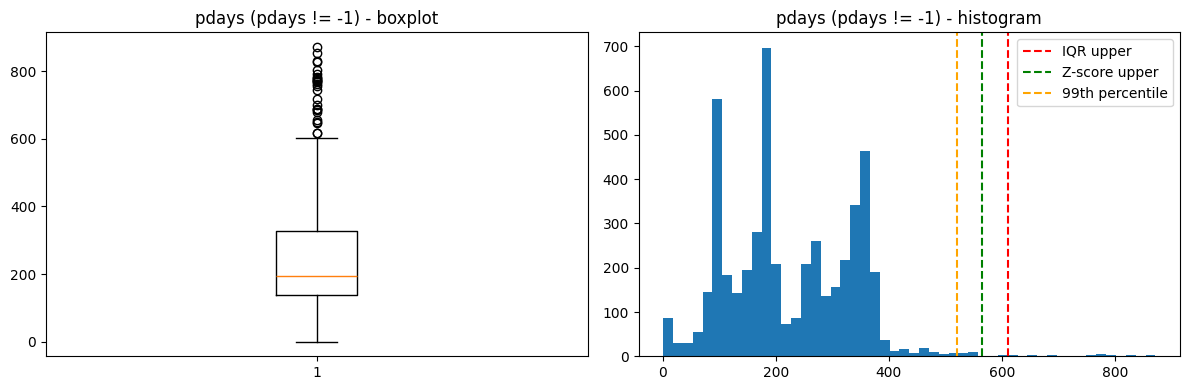

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(p)
axes[0].set_title('pdays (pdays != -1) - boxplot')
axes[1].hist(p, bins=50)
axes[1].axvline(iqr_hi, color='red', linestyle='--', label='IQR upper')
axes[1].axvline(z_hi, color='green', linestyle='--', label='Z-score upper')
axes[1].axvline(pct_hi, color='orange', linestyle='--', label='99th percentile')
axes[1].set_title('pdays (pdays != -1) - histogram')
axes[1].legend()
plt.tight_layout()
plt.show()

#### pdays 이상치 판단
- 이전 연락 고객(Train 4,938건)을 대상으로 탐지한 결과 IQR 27건(0.55%, 609.9일 초과), Z-score 31건(0.63%, 565.3일 초과), 백분위수 99건(2.00%, 7.4일 미만 또는 521.0일 초과)이 탐지됨.
- IQR과 Z-score는 약 570~610일 이상으로 비슷한 기준을 보여 서로의 결과를 뒷받침함. 분포의 왜도가 0.64로 크게 치우치지 않아 Z-score를 적용해도 무리가 없음.
- 백분위수는 정의상 항상 약 2%를 잘라내므로, 이상치 존재 여부를 판단하기보다 클리핑 기준을 정하는 용도로 활용함.
- 최대값 871일(약 2.4년)은 현실적으로 가능한 값이고, 값이 연속적으로 분포하며, 이상치 구간의 가입률(25~29%)도 정상 구간(약 22.6%)과 큰 차이가 없음.
- **결론: pdays는 삭제하지 않고 유지**하며, Logistic Regression 적용 시 IQR 또는 Z-score 상한에서 클리핑을 검토함.
- 참고로 -1을 포함한 전체 데이터에 Z-score를 적용하면 1,022건이 탐지되는데, 이는 이전 연락 이력이 있다는 이유만으로 잡힌 결과이므로 의미가 없음.

#### 이상치 전처리
- IQR(1.5배) 기준으로 Train 데이터(26,931건)를 점검한 결과 age 287건(1.07%), balance 2,829건(10.50%), campaign 1,821건(6.76%)의 이상치가 탐지되었으나, 도메인 규칙상 오류값은 없어 모두 실제로 존재할 수 있는 극단값으로 판단하였다. age는 18~93세로 현실적이며, IQR 상한(70.5세)을 넘는 고객의 가입률이 44.3%로 정상 범위(11.3%)보다 높아 유지하였다. balance의 음수 잔고(8.31%)와 고액 잔고(최대 98,417)도 실제 가능한 값이므로 유지하되, 분포가 크게 치우쳐 있어 Logistic Regression 적용 시 로그 변환을 검토한다. campaign은 IQR 상한(6회)을 넘는 고객의 가입률이 5.1%로 정상 범위(12.2%)보다 낮아 유의미한 정보로 보고 유지하되, Logistic Regression 적용 시 클리핑을 검토한다. day는 이상치가 없었다.
- previous는 최대값 275가 다음으로 큰 값(58)과 크게 동떨어져 있어 입력 오류로 판단하고, 100 초과 값을 오류로 간주하는 규칙을 세 데이터셋에 동일하게 적용하여 삭제하였다(Train 1건, 삭제 후 Train 26,930건).
- pdays는 -1(이전 연락 없음)을 제외한 이전 연락 고객만을 대상으로 IQR, Z-score, 백분위수 세 가지 방법으로 탐지한 결과 각각 27건(0.55%), 31건(0.63%), 99건(2.00%)이 탐지되었다. 그러나 최대값 871일은 현실적으로 가능한 범위이며 값이 연속적으로 분포하고, 이상치 구간의 가입률도 정상 구간과 큰 차이가 없어 삭제하지 않고 유지하였다.